In [1]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import scipy
import torch
import torch.nn as nn

import pymc
from magnus import NSFeas
import sys
from pathlib import Path
from helpers import Trellis, Corner, train_surrogate, generate_sobol_points
from plotstyle import setup, FIGURES_DIR
setup()

In [2]:
# Helpers
def theta_nominal():
    T_REF = 328.15
    k_1_ref = 8.84e-3 * 60 * 0.5 # 1/min
    k_2_ref = k_1_ref / 8
    theta_1 = k_1_ref * np.exp(E_1 / (R_GAS * T_REF))
    theta_2 = k_2_ref * np.exp(E_2 / (R_GAS * T_REF))

    return theta_1, theta_2

In [3]:
# Global Constants
E_1 = 48_000 # J/mol (activation energy first reaction)
E_2 = 55_000 # J/mol (activation energy second reaction)
R_GAS = 8.314 # J/K/mol
T_LO, T_HI, TAU_LO, TAU_HI = 298.15, 353.15, 2, 30 # K, K, min, min
DCB_FRACTION_CAP, MCB_FLOOR, CONV_FLOOR = 0.05, 0.55, 0.70
th_1, th_2 = theta_nominal()
C_A0 = 11.28 # mol/L; benzene feed concentration
N_FEAS_REQ = 8192
N_UNIT_OP_SBL = 8192 # number of training data points

In [4]:
# Calculation of arrhenius prefactors (T-dependent)

def compute_k(T_1: float, T_2: float):
    k_1_R1 = th_1 * np.exp(- E_1 / (R_GAS * T_1))
    k_2_R1 = th_2 * np.exp(- E_2 / (R_GAS * T_1))
    k_1_R2 = th_1 * np.exp(- E_1 / (R_GAS * T_2))
    k_2_R2 = th_2 * np.exp(- E_2 / (R_GAS * T_2))

    return (k_1_R1, k_2_R1), (k_1_R2, k_2_R2)

In [5]:
# Counters (for stat purposes only)
M1_counter = R1_counter = R2_counter = S1_counter = 0

In [6]:
# Mixer
def M1(rho: float, c_R: tuple, c_F: tuple):
    global M1_counter; M1_counter += 1
    c_A_R, c_B_R, c_C_R = c_R[0], c_R[1], c_R[2]
    c_A_F, c_B_F, c_C_F = c_F[0], c_F[1], c_F[2]
    c_A_alpha = rho * c_A_R + (1 - rho) * c_A_F
    c_B_alpha = rho * c_B_R + (1 - rho) * c_B_F
    c_C_alpha = rho * c_C_R + (1 - rho) * c_C_F

    return c_A_alpha, c_B_alpha, c_C_alpha

In [7]:
# CSTR1
def R1(c_alpha: tuple, k_R1: tuple, tau_1: float):
    global R1_counter; R1_counter += 1
    k_1_R1, k_2_R1 = k_R1
    c_A_alpha, c_B_alpha, c_C_alpha = c_alpha

    c_A_R1 = c_A_alpha / (1 + k_1_R1 * tau_1)
    c_B_R1 = (c_B_alpha + k_1_R1 * c_A_R1 * tau_1) / (1 + k_2_R1 * tau_1)
    c_C_R1 = c_C_alpha + k_2_R1 * c_B_R1 * tau_1
    
    return c_A_R1, c_B_R1, c_C_R1

In [8]:
# CSTR2
def R2(c_R1: tuple, k_R2: tuple, tau_2: float):
    global R2_counter; R2_counter += 1
    c_A_R1, c_B_R1, c_C_R1 = c_R1
    k_1_R2, k_2_R2 = k_R2

    c_A_R2 = c_A_R1 / (1 + k_1_R2 * tau_2)
    c_B_R2 = (c_B_R1 + k_1_R2 * c_A_R2 * tau_2) / (1 + k_2_R2 * tau_2)
    c_C_R2 = c_C_R1 + k_2_R2 * c_B_R2 * tau_2

    return c_A_R2, c_B_R2, c_C_R2

In [9]:
# Splitter
def S1(c_R2: tuple):
    # NOTE: rho: recycle ratio, dens: density
    global S1_counter; S1_counter += 1
    c_A_R2, c_B_R2, c_C_R2 = c_R2
    M_A, M_B, M_C = 78.11, 112.56, 147.00 # g/mol
    dens_A, dens_B, dens_C = 0.88e3, 1.11e3, 1.30e3 # g/L
    s_A, s_B, s_C = 0.7, 0.35, 0.20 # these values are for illustration
    summands = [M_A / dens_A  * s_A * c_A_R2, M_B / dens_B  * s_B * c_B_R2, M_C / dens_C  * s_C * c_C_R2]
    rho = sum(summands)
    c_A_R = s_A * c_A_R2 / rho
    c_B_R = s_B * c_B_R2 / rho
    c_C_R = s_C * c_C_R2 / rho

    return (c_A_R, c_B_R, c_C_R), rho

In [10]:
def get_informed_guess():
    """Make informed initial guess by finding nearest feasible configuration
    First value: is informed guess available (NONE if no feasible points found yet),
    Second value: rho_ig,
    Third value: c_R_ig
    TODO: implement this if fixed point iterations are slow
    """
    return None, None, None

In [11]:
def is_converged(guess, real):
    """Convergence Metric"""
    real = np.array(real)
    guess = np.array(guess)
    diff = np.abs(real - guess)
    diff_norm = diff / (np.absolute(real) + 1e-8)
    max_vio = diff_norm.max()

    return max_vio < 1e-3

In [12]:
class SimResult:
    def __init__(self, converged, c_alpha, c_R1, c_R2, c_R, rho, c_F):
        self.converged = converged
        self.c_alpha = c_alpha
        self.c_R1 = c_R1
        self.c_R2 = c_R2
        self.c_R = c_R
        self.c_F = c_F
        self.rho = rho

In [13]:
# Simulate forward (to be called by Nested Sampler)
def sim_forward_real(T_1, tau_1, T_2, tau_2):
    it, MAX_ITER = 0, 1000
    c_F = C_A0, 0, 0 # mol/L (pure benzene feed)
    # initial guesses (ig)
    inf_guess = get_informed_guess()
    rho_ig = 0.3 if not inf_guess[0] else inf_guess[1]
    c_R_ig = (5, 2, 1) if not inf_guess[0] else inf_guess[2]

    # k need fresh computatation at each configuration (T-dependent)
    k_R1, k_R2 = compute_k(T_1, T_2)

    while (it < MAX_ITER):
        it += 1
        c_alpha     = M1(rho=rho_ig, c_R=c_R_ig, c_F=c_F)
        c_R1        = R1(c_alpha=c_alpha, k_R1=k_R1, tau_1=tau_1)
        c_R2        = R2(c_R1=c_R1, k_R2=k_R2, tau_2=tau_2)
        c_R, rho    = S1(c_R2=c_R2)
        conv = is_converged(guess=[*c_R_ig, rho_ig], real=[*c_R, rho])
        if conv:
            return SimResult(converged=True, c_alpha=c_alpha,
                             c_R1=c_R1, c_R2=c_R2,
                             c_R=c_R, c_F=c_F, rho=rho)

        # update to next tear iteration
        c_R_ig, rho_ig = c_R, rho

    # not converged within MAX_ITER
    return SimResult(False, None, None, None, None, None, None)

In [14]:
# Interface Adapter for real unit operations
def model_simultaneous_real(x):
    """Model of CSTR-cascade flowsheet using acutal unit operations."""
    T_1, tau_1, T_2, tau_2 = x
    sim_res = sim_forward_real(T_1=T_1, tau_1=tau_1, T_2=T_2, tau_2=tau_2)

    if (not sim_res.converged) or (sim_res.rho < 0) or (sim_res.rho > 1):
        # return *something* guaranteed to be infeasible
        return [-1e-8, -1e-8, -1e-8, -1e-8, -1e-8, -1e-8]
    c_A_R1, c_B_R1, c_C_R1 = sim_res.c_R1 
    c_A_R2, c_B_R2, c_C_R2 = sim_res.c_R2

    return [c_A_R1, c_A_R2, c_B_R1, c_B_R2, c_C_R1, c_C_R2]

In [15]:
def simultaneous_NS(model, numlive=N_FEAS_REQ, numprop=256):
    """Performs nested sampling on entire search space"""
    # Nested Sampling of [T1, tau1, T2, tau2] space
    DAG = pymc.FFGraph()
    DAG.options.MAXTHREAD = 1

    T_1, tau_1 = DAG.add_var('T_1'), DAG.add_var('tau_1')
    T_2, tau_2 = DAG.add_var('T_2'), DAG.add_var('tau_2')

    op = pymc.FFCustom()
    op.set_D_eval(model)
    # applying the operation adds nodes to DAG
    outs = op(ndep=6, var=[T_1, tau_1, T_2, tau_2], uid=0)
    c_A_R1, c_A_R2, c_B_R1, c_B_R2, c_C_R1, c_C_R2 = outs

    # Setup nested sampler
    NS = NSFeas()
    NS.options.MAXTHREAD = 1           # Python callback + GIL: must be 1
    NS.options.DISPLEVEL = 1           # console verbosity
    NS.options.DISPITER  = 25          # rows per N iterations in table (cosmetic)
    NS.options.NUMLIVE   = numlive     # #Live Points
    NS.options.NUMPROP   = numprop     # Proposals per iteration
    NS.options.MAXITER   = 0           # iterate until complete (hard iteration limit else)

    NS.set_dag(DAG)
    # contols for variables and bounds
    NS.set_control([T_1, tau_1, T_2, tau_2], [T_LO, TAU_LO, T_LO, TAU_LO], [T_HI, TAU_HI, T_HI, TAU_HI])
    NS.set_constraint([c_C_R1 / (c_A_R1 + c_B_R1 + c_C_R1) - DCB_FRACTION_CAP,
                    MCB_FLOOR - c_B_R2 / (c_A_R2 + c_B_R2 + c_C_R2), 
                    CONV_FLOOR - (1 - c_A_R2 / C_A0)])
    NS.setup()
    NS.sample()
    NS.stats.display()
    # assert M1_counter == R1_counter == R2_counter == S1_counter and M1_counter != 0
    return NS

NS_simultaneous = simultaneous_NS(model_simultaneous_real)


** INITIALIZING LIVE POINTS (8192)      0.23 SEC

Iterate        Contour #Feas    #Dead         Factor
----------------------------------------------------
      0     7.6639e-01   103        0     3.0000e-01
     25     3.1804e-01   180     4744     2.6720e-01
     50     2.1590e-01   267     7711     2.4853e-01
     75     1.6380e-01   348     9876     2.3573e-01
    100     1.3188e-01   438    11595     2.2604e-01
    125     1.1174e-01   522    13018     2.1832e-01
    150     9.5777e-02   614    14268     2.1176e-01
    175     8.4120e-02   707    15382     2.0608e-01
    200     7.4876e-02   795    16398     2.0103e-01
    225     6.7730e-02   889    17289     1.9671e-01
    250     6.1479e-02   988    18136     1.9268e-01
    275     5.6028e-02  1083    18910     1.8907e-01
    300     5.1590e-02  1186    19648     1.8570e-01
    325     4.5047e-02  1371    20723     1.8089e-01
    350     3.7683e-02  1649    22083     1.7498e-01
    375     3.2098e-02  1920    23343     1.6968

In [16]:
print("M1:", M1_counter, "R1:", R1_counter, "R2:", R2_counter, "S1:", S1_counter)
n_iter_sim = R1_counter # tear iterations of the simultaneous run (one iteration = one call of each unit)
# reset counters
M1_counter = R1_counter = R2_counter = S1_counter = 0

M1: 900627 R1: 900627 R2: 900627 S1: 900627


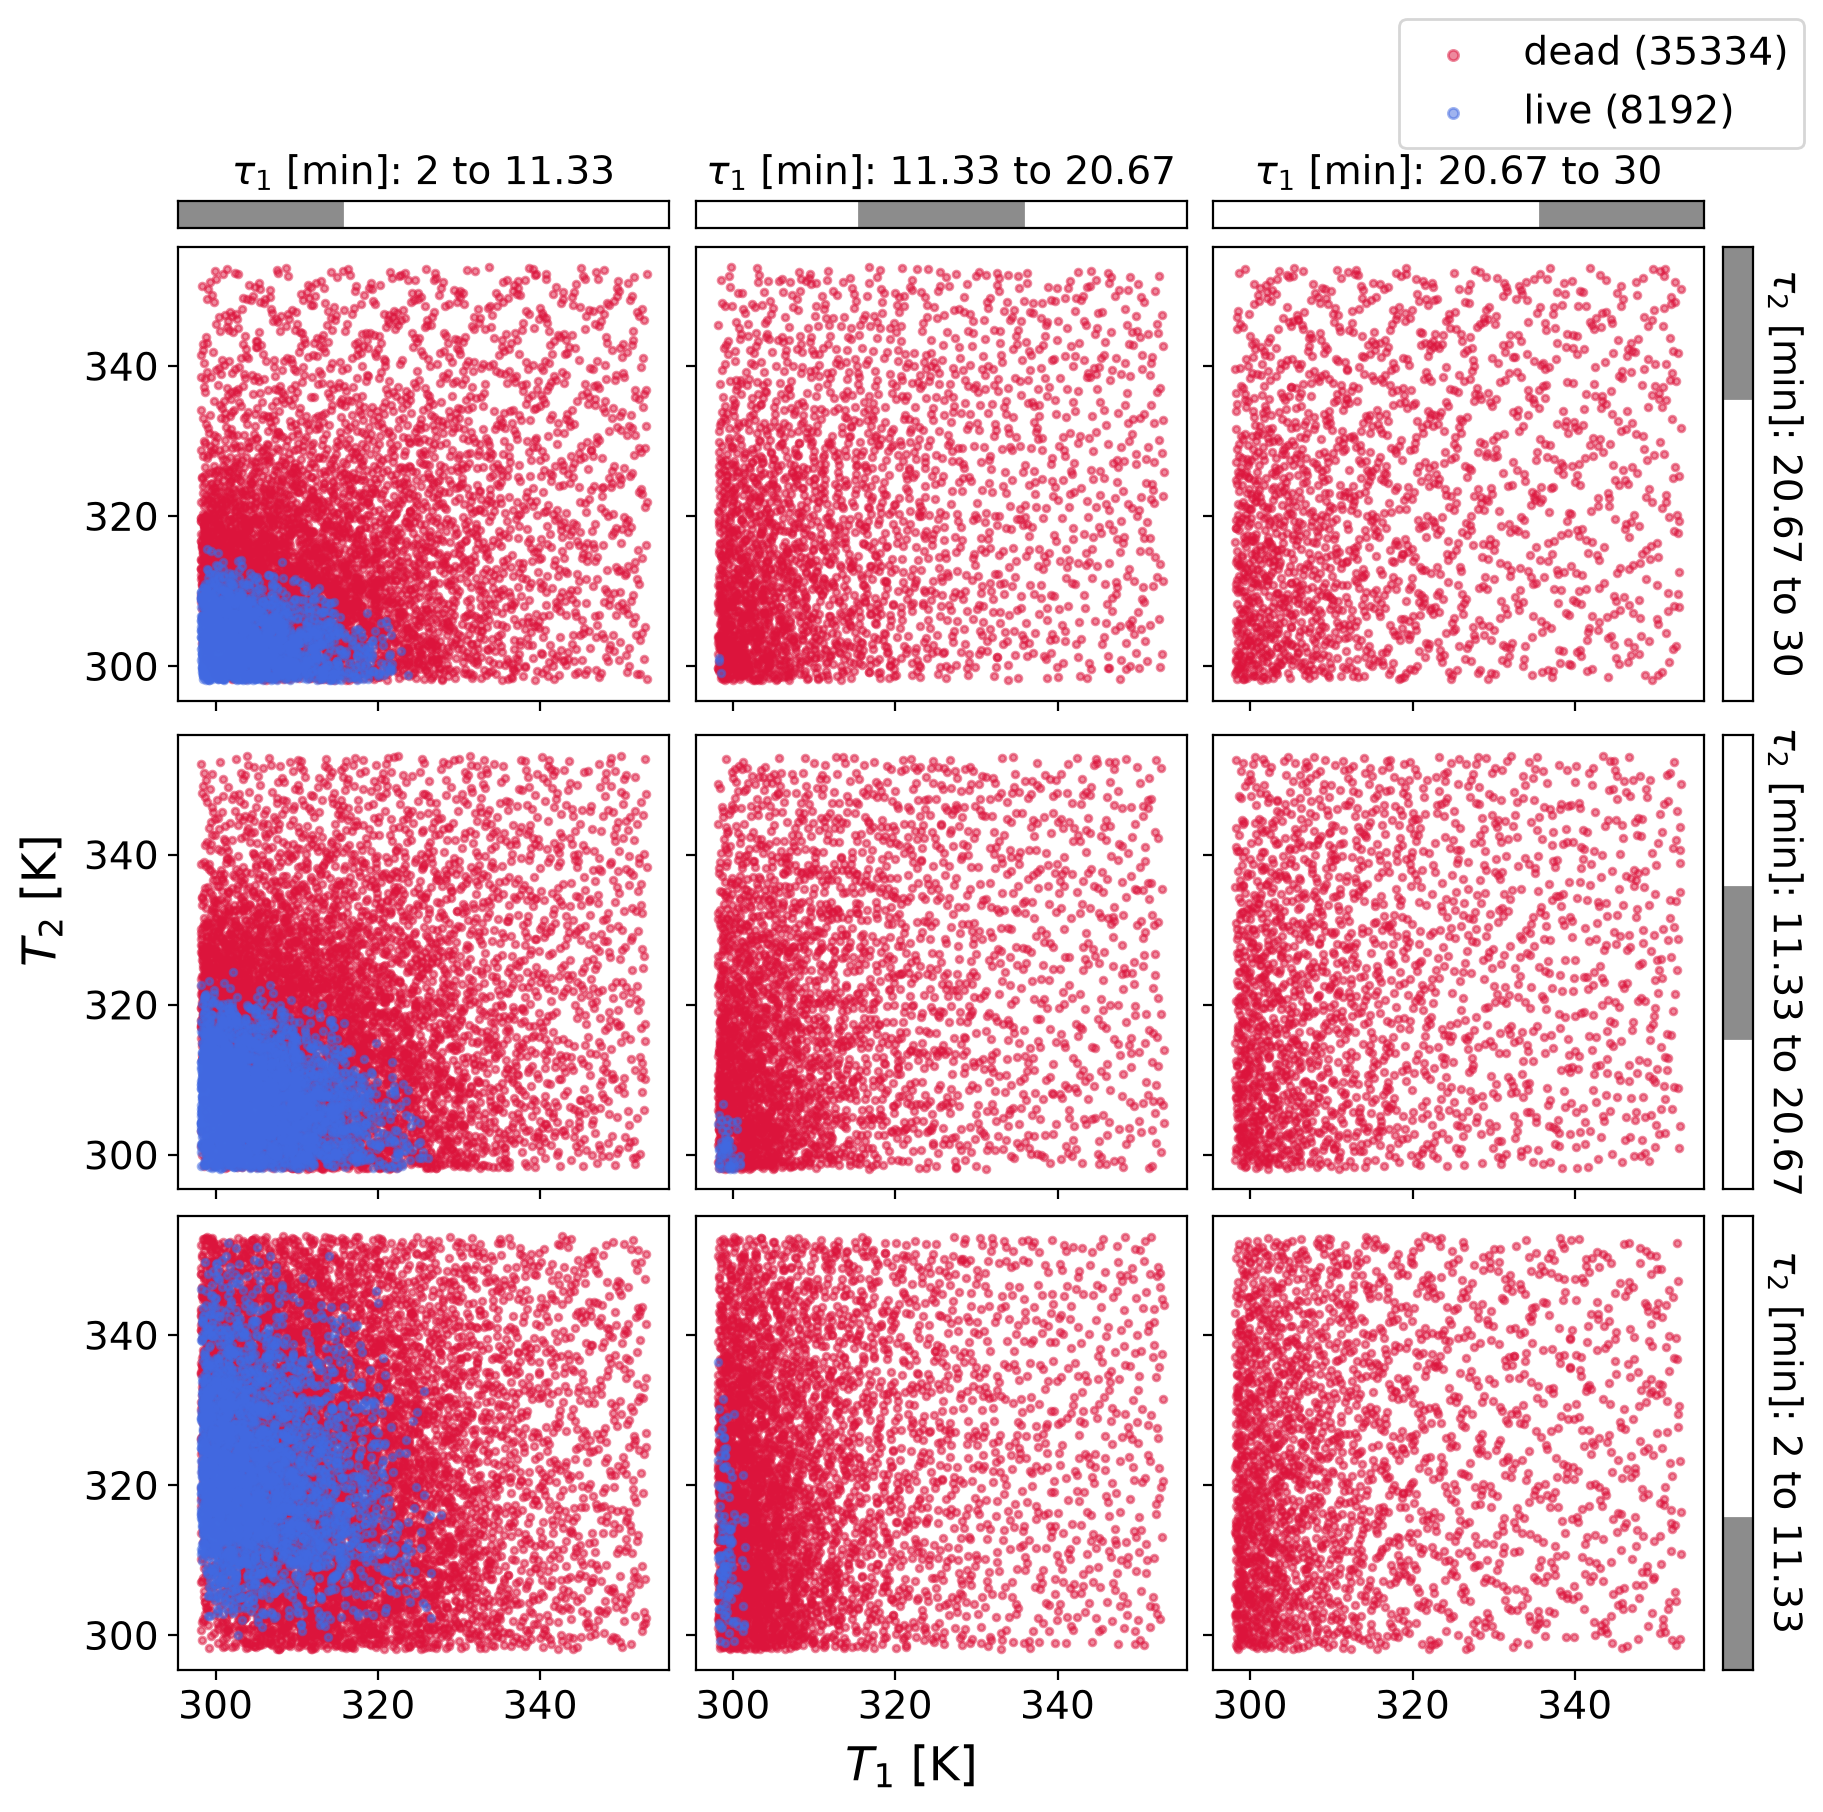

In [17]:
def simultaneous_trellis_plot():
    # NS.livepoints returns: (points[N, nu],  crit[N, 1],  prob[N, 1],  aux[N, 1])
    live_pts, live_feas, *_ = NS_simultaneous.live_points
    dead_pts, dead_feas, *_ = NS_simultaneous.dead_points

    T_1, tau_1, T_2, tau_2 = range(4)
    grid = Trellis(np.linspace(TAU_LO, TAU_HI, 4), np.linspace(TAU_LO, TAU_HI, 4),      # bin edges: tau_1, tau_2
                   xlabel="$T_1$ [K]", ylabel=r"$T_2$ [K]",
                   col_label=r"$\tau_1$ [min]", row_label=r"$\tau_2$ [min]")
    grid.scatter(dead_pts[:, T_1], dead_pts[:, T_2], dead_pts[:, tau_1], dead_pts[:, tau_2],
                 color="crimson", s=6, alpha=0.5,   label=f"dead ({len(dead_pts)})")
    grid.scatter(live_pts[:, T_1], live_pts[:, T_2], live_pts[:, tau_1], live_pts[:, tau_2],
                 color="royalblue", s=6, alpha=0.5, label=f"live ({len(live_pts)})")
    grid.fig.legend(loc="outside upper right")

simultaneous_trellis_plot()

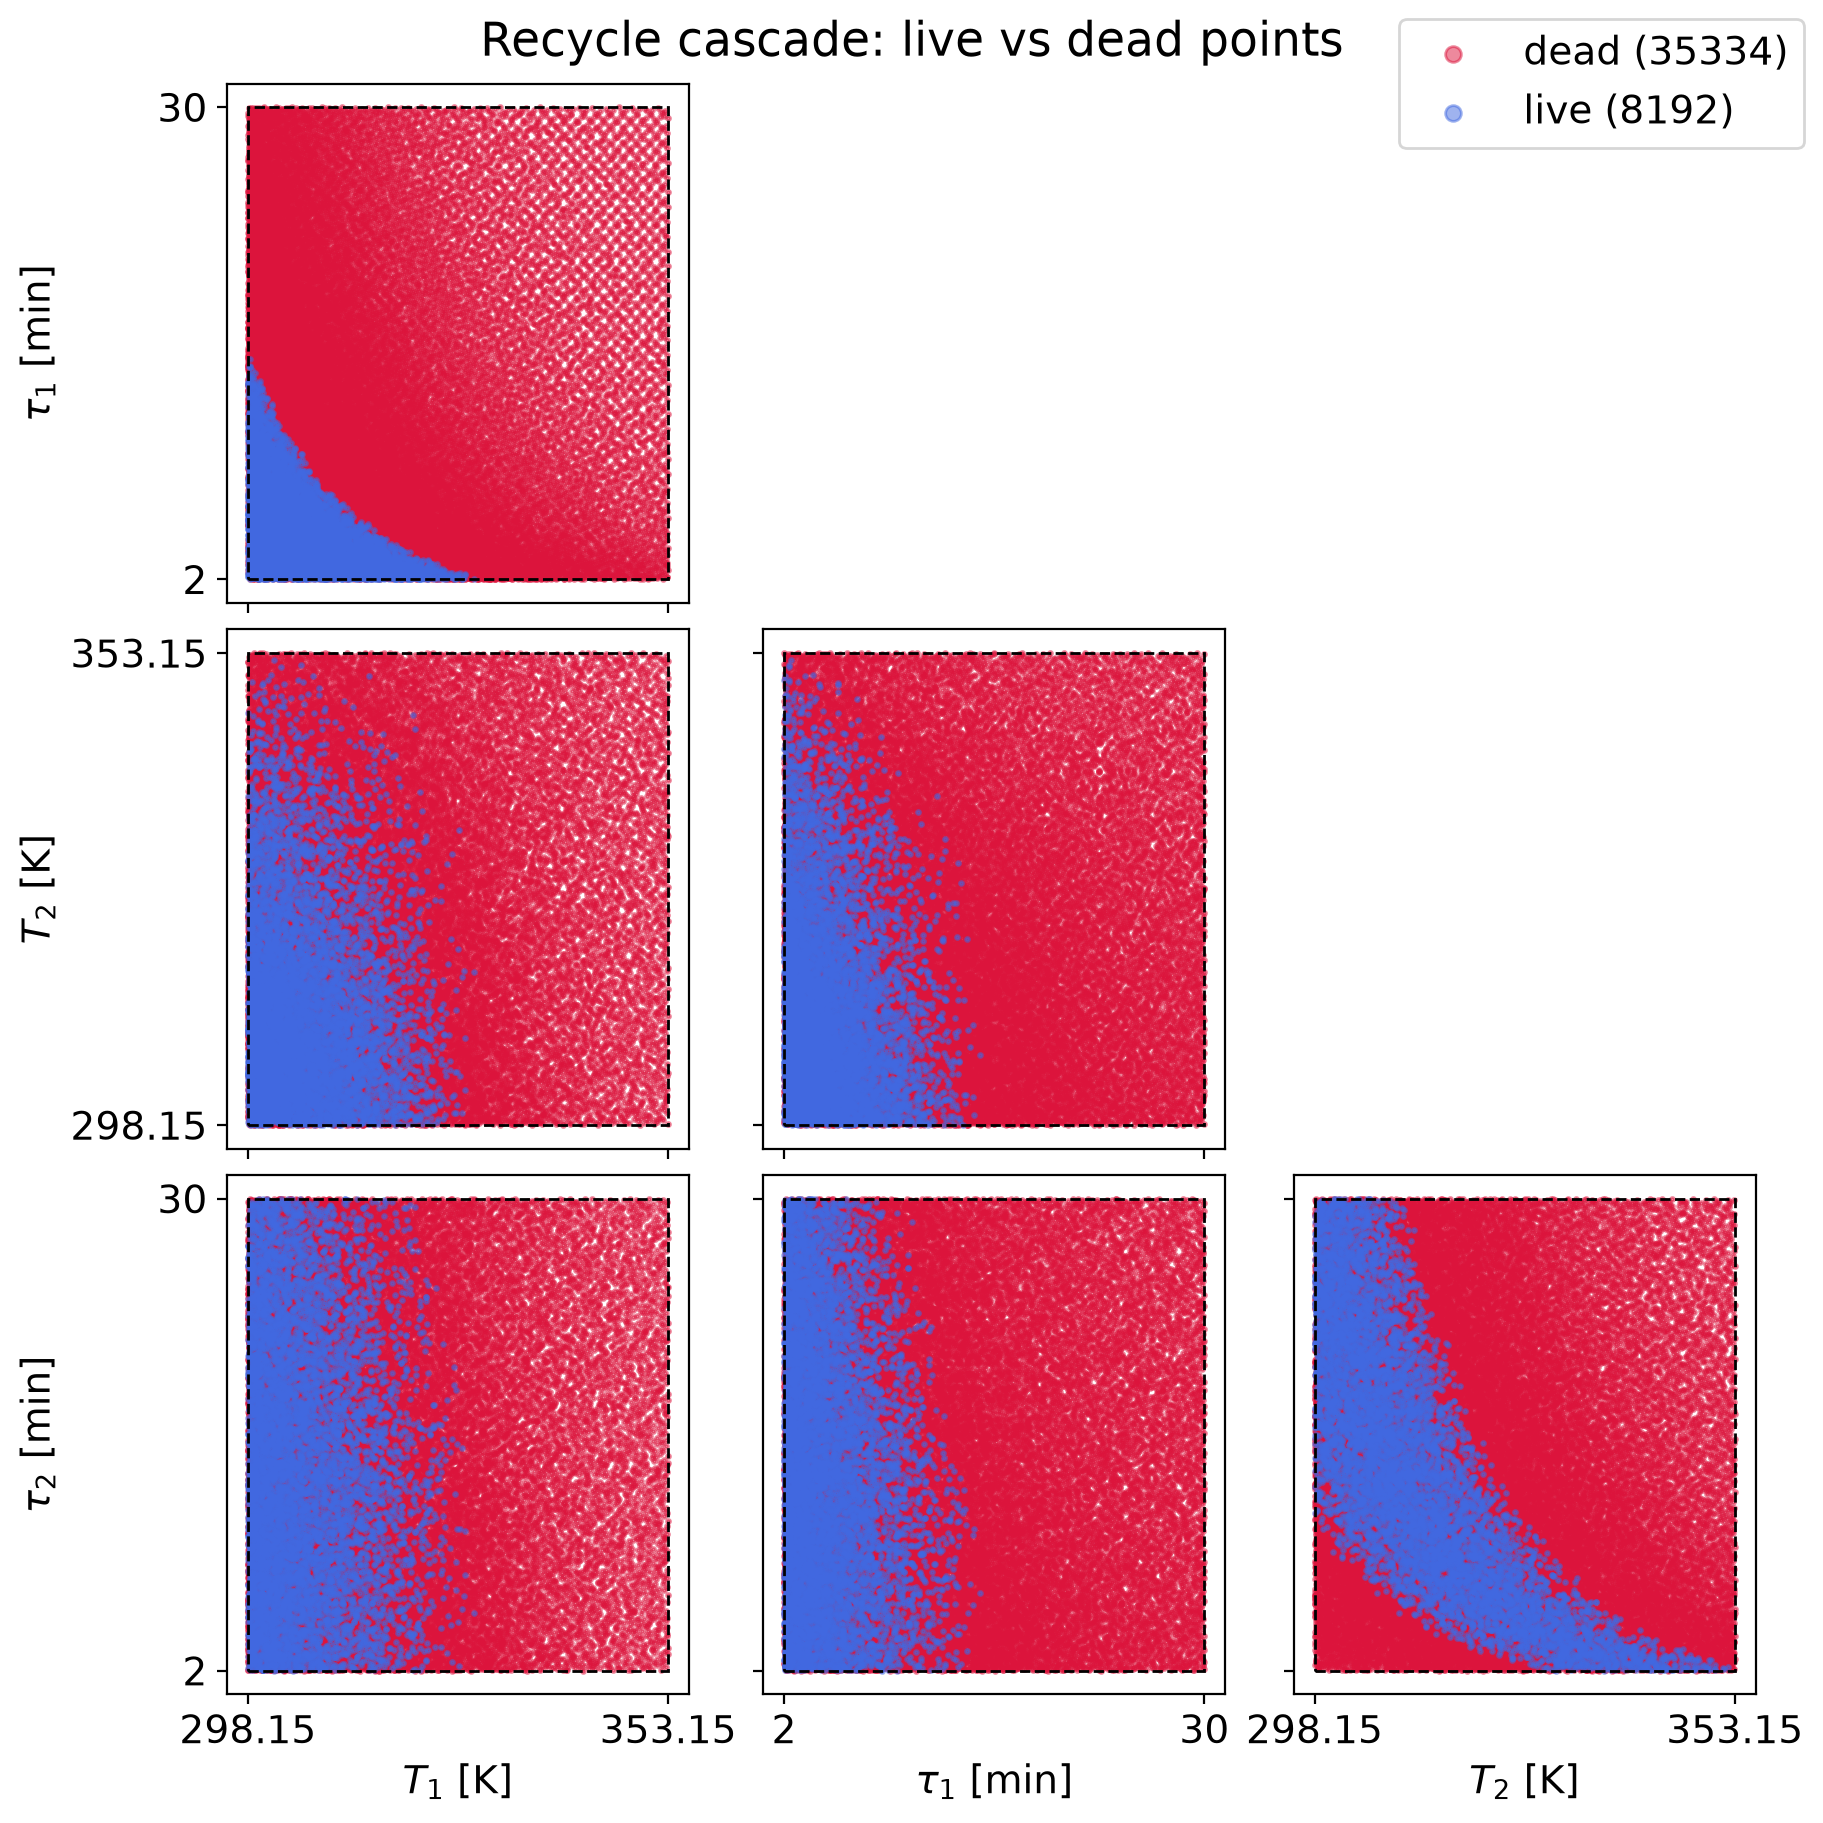

In [18]:
def simultaneous_corner_plot():
    live_pts, live_feas, *_ = NS_simultaneous.live_points
    dead_pts, dead_feas, *_ = NS_simultaneous.dead_points
    grid = Corner([r"$T_1$ [K]", r"$\tau_1$ [min]", r"$T_2$ [K]", r"$\tau_2$ [min]"],
                  [[T_LO, TAU_LO, T_LO, TAU_LO], [T_HI, TAU_HI, T_HI, TAU_HI]])
    # painter's order: dead below, live (feasible) on top
    grid.scatter(dead_pts, s=2, alpha=0.5, color="crimson",   label=f"dead ({len(dead_pts)})")
    grid.scatter(live_pts, s=2, alpha=0.5, color="royalblue", label=f"live ({len(live_pts)})")
    grid.fig.legend(markerscale=4)
    grid.fig.suptitle(r"Recycle cascade: live vs dead points")

simultaneous_corner_plot()

## Decomposition based sampling

### Inlet Bounds Generation

In [19]:
def initialize_search_space():
    k_bounds = np.array([[T_LO, TAU_LO, T_LO, TAU_LO], [T_HI, TAU_HI, T_HI, TAU_HI]]) # T1, tau1, T2, tau2
    v_train = generate_sobol_points(40, k_bounds)
    results, it0 = {}, R1_counter
    for point in v_train:
        T_1, tau_1, T_2, tau_2 = point
        results[tuple(point)] = sim_forward_real(T_1=T_1, tau_1=tau_1, T_2=T_2, tau_2=tau_2)
    return results, R1_counter - it0
initialization_results, n_iter_init = initialize_search_space()

In [20]:
# bounds for KU_i
class UnitOpBounds:
    def __init__(self, unit_name):
        self.unit_name = unit_name
        self.bounds = {}
    def add(self, var: str):
        self.bounds[var] = [float('inf'), float('-inf')] # lb, ub
    def update(self, var, val):
        assert var in self.bounds
        self.bounds[var] = [min(self.bounds[var][0], val), max(self.bounds[var][1], val)]
    def inflate(self, infl):
        """inflates by infl symmetrically, clamping at zero"""
        for b in self.bounds.values():
            span = b[1] - b[0]
            b[0], b[1] = max(b[0] - infl * span, 0), b[1] + infl * span

In [21]:
# Note: m1 has four inputs
m1_init_bounds = UnitOpBounds('M1')
m1_init_bounds.add('rho')
m1_init_bounds.add('c_A_R')
m1_init_bounds.add('c_B_R')
m1_init_bounds.add('c_C_R')

r1_init_bounds = UnitOpBounds('R1')
r1_init_bounds.add('c_A_alpha')
r1_init_bounds.add('c_B_alpha')
r1_init_bounds.add('c_C_alpha')

r2_init_bounds = UnitOpBounds('R2')
r2_init_bounds.add('c_A_R1')
r2_init_bounds.add('c_B_R1')
r2_init_bounds.add('c_C_R1')

s1_init_bounds = UnitOpBounds('S1')
s1_init_bounds.add('c_A_R2')
s1_init_bounds.add('c_B_R2')
s1_init_bounds.add('c_C_R2')

In [22]:
for v in initialization_results.values():
    m1_init_bounds.update('c_A_R', v.c_R[0])
    m1_init_bounds.update('c_B_R', v.c_R[1])
    m1_init_bounds.update('c_C_R', v.c_R[2])
    m1_init_bounds.update('rho', v.rho)

    r1_init_bounds.update('c_A_alpha', v.c_alpha[0])
    r1_init_bounds.update('c_B_alpha', v.c_alpha[1])
    r1_init_bounds.update('c_C_alpha', v.c_alpha[2])

    r2_init_bounds.update('c_A_R1', v.c_R1[0])
    r2_init_bounds.update('c_B_R1', v.c_R1[1])
    r2_init_bounds.update('c_C_R1', v.c_R1[2])

    s1_init_bounds.update('c_A_R2', v.c_R2[0])
    s1_init_bounds.update('c_B_R2', v.c_R2[1])
    s1_init_bounds.update('c_C_R2', v.c_R2[2])

# inflate bounds
m1_init_bounds.inflate(0.15)
r1_init_bounds.inflate(0.15)
r2_init_bounds.inflate(0.15)
s1_init_bounds.inflate(0.15)

### Sampling Per Unit (Sobol)

In [23]:
# Modeling M1
def generate_train_data_M1():
    """Generates training data for unit M1. Sobol sampling"""
    bounds = m1_init_bounds.bounds
    m1_sampling_bounds = np.array([[bounds['rho'][0], bounds['c_A_R'][0], bounds['c_B_R'][0], bounds['c_C_R'][0]], 
                                   [bounds['rho'][1], bounds['c_A_R'][1], bounds['c_B_R'][1], bounds['c_C_R'][1]]]) 
    inputs = generate_sobol_points(n=N_UNIT_OP_SBL, bounds=m1_sampling_bounds)
    c_F = (C_A0, 0, 0)

    records_x = []
    records_y = []

    for x in inputs:
        rho, c_A_R, c_B_R, c_C_R = x
        y = M1(rho=rho, c_R=(c_A_R, c_B_R, c_C_R), c_F=c_F)
        records_x.append(list(x))
        records_y.append(list(y))
    return np.array(records_x), np.array(records_y)

M1_training_data = generate_train_data_M1()

In [24]:
# Modeling R1
def generate_train_data_R1():
    """Generates training data for unit R1. Sobol sampling"""
    bounds = r1_init_bounds.bounds
    r1_sampling_bounds = np.array([[T_LO, TAU_LO,  bounds['c_A_alpha'][0], bounds['c_B_alpha'][0], bounds['c_C_alpha'][0]], 
                                   [T_HI, TAU_HI, bounds['c_A_alpha'][1], bounds['c_B_alpha'][1], bounds['c_C_alpha'][1]]]) 
    inputs = generate_sobol_points(n=N_UNIT_OP_SBL, bounds=r1_sampling_bounds)

    records_x = []
    records_y = []

    for x in inputs:
        T_1, tau_1, c_A_alpha, c_B_alpha, c_C_alpha = x
        k_R1 = compute_k(T_1, 42)[0]
        y = R1((c_A_alpha, c_B_alpha, c_C_alpha), k_R1, tau_1)
        records_x.append(list(x))
        records_y.append(list(y))
    return np.array(records_x), np.array(records_y)

R1_training_data = generate_train_data_R1()

In [25]:
# Modeling R2
def generate_train_data_R2():
    """Generates training data for unit R2. Sobol sampling"""
    bounds = r2_init_bounds.bounds
    r2_sampling_bounds = np.array([[T_LO, TAU_LO,  bounds['c_A_R1'][0], bounds['c_B_R1'][0], bounds['c_C_R1'][0]], 
                                   [T_HI, TAU_HI, bounds['c_A_R1'][1], bounds['c_B_R1'][1], bounds['c_C_R1'][1]]]) 
    inputs = generate_sobol_points(n=N_UNIT_OP_SBL, bounds=r2_sampling_bounds)

    records_x = []
    records_y = []

    for x in inputs:
        T_2, tau_2, c_A_R1, c_B_R1, c_C_R1 = x
        k_R2 = compute_k(42, T_2)[1]
        y = R2((c_A_R1, c_B_R1, c_C_R1), k_R2, tau_2)
        records_x.append(list(x))
        records_y.append(list(y))
    return np.array(records_x), np.array(records_y)

R2_training_data = generate_train_data_R2()

In [26]:
# Modeling S1
def generate_train_data_S1():
    """Generates training data for unit S1, based on sobol sampled points within bounds."""
    bounds = s1_init_bounds.bounds
    s1_sampling_bounds = np.array([[bounds['c_A_R2'][0], bounds['c_B_R2'][0], bounds['c_C_R2'][0]], 
                                   [bounds['c_A_R2'][1], bounds['c_B_R2'][1], bounds['c_C_R2'][1]]]) 
    inputs = generate_sobol_points(n=N_UNIT_OP_SBL, bounds=s1_sampling_bounds)

    records_x = []
    records_y = []

    for x in inputs:
        c_A_R2, c_B_R2, c_C_R2 = x
        y = S1(c_R2=(c_A_R2, c_B_R2, c_C_R2))
        records_x.append(list(x))
        records_y.append(list([*y[0], y[1]]))
    return np.array(records_x), np.array(records_y)

S1_training_data = generate_train_data_S1()

### Train ANN Surrogates On Sampled Data Per Unit

In [27]:
surr_M1, _, _ = train_surrogate(*M1_training_data, path="surr_M1")  # (model, rmse, Y_oof)

width 64 (73 s)   CV rmse/std per width: 4: 0.0175, 8: 0.0066, 16: 0.0035, 32: 0.0027, 64: 0.0024, 128: 0.0024
  y0                         0.002    0.05 % of range
  y1                         0.002    0.06 % of range
  y2                         0.002    0.05 % of range


In [28]:
surr_R1, _, _ = train_surrogate(*R1_training_data, path="surr_R1")

width 64 (76 s)   CV rmse/std per width: 4: 0.1013, 8: 0.0146, 16: 0.0051, 32: 0.0036, 64: 0.0028, 128: 0.0046
  y0                         0.004    0.06 % of range
  y1                         0.004    0.07 % of range
  y2                         0.005    0.05 % of range


In [29]:
surr_R2, _, _ = train_surrogate(*R2_training_data, path="surr_R2")

width 64 (74 s)   CV rmse/std per width: 4: 0.1344, 8: 0.0264, 16: 0.0133, 32: 0.0075, 64: 0.0047, 128: 0.0052
  y0                         0.005    0.08 % of range
  y1                         0.009    0.10 % of range
  y2                         0.013    0.07 % of range


In [30]:
surr_S1, _, _ = train_surrogate(*S1_training_data, path="surr_S1")

width 32 (47 s)   CV rmse/std per width: 4: 0.0829, 8: 0.0231, 16: 0.0082, 32: 0.0055, 64: 0.0059
  y0                         0.010    0.09 % of range
  y1                         0.010    0.11 % of range
  y2                         0.013    0.15 % of range
  y3                         0.000    0.06 % of range


In [31]:
# Surrogate version: simulate forward (to be called by Nested Sampler)
def sim_forward_surr(T_1, tau_1, T_2, tau_2):
    it, MAX_ITER = 0, 1000
    c_F = C_A0, 0, 0 # mol/L (pure benzene feed)
    # initial guesses (ig)
    inf_guess = get_informed_guess()
    rho_ig = 0.3 if not inf_guess[0] else inf_guess[1]
    c_R_ig = (5, 2, 1) if not inf_guess[0] else inf_guess[2]

    while (it < MAX_ITER):
        it += 1
        c_alpha = surr_M1((rho_ig, *c_R_ig))
        c_R1 = surr_R1((T_1, tau_1, *c_alpha))
        c_R2 = surr_R2((T_2, tau_2, *c_R1))
        *c_R, rho = surr_S1(c_R2)
        conv = is_converged(guess=[*c_R_ig, rho_ig], real=[*c_R, rho])

        if conv:
            return SimResult(converged=True, c_alpha=c_alpha,
                             c_R1=c_R1, c_R2=c_R2,
                             c_R=c_R, c_F=c_F, rho=rho)

        # update to next tear iteration
        c_R_ig, rho_ig = c_R, rho

    # not converged within MAX_ITER
    return SimResult(False, None, None, None, None, None, None)

In [32]:
# Interface Adapter for surrogate unit operations
def model_simultaneous_surr(x):
    """
    Model of CSTR-cascade flowsheet using surrogate unit operations.
    """
    T_1, tau_1, T_2, tau_2 = x[0], x[1], x[2], x[3]
    sim_res = sim_forward_surr(T_1=T_1, tau_1=tau_1, T_2=T_2, tau_2=tau_2)

    if not sim_res.converged or sim_res.rho < 0 or sim_res.rho > 1:
        # return *something* guaranteed to be infeasible
        return [-1e-8, -1e-8, -1e-8, -1e-8, -1e-8, -1e-8]
    c_A_R1, c_B_R1, c_C_R1 = sim_res.c_R1
    c_A_R2, c_B_R2, c_C_R2 = sim_res.c_R2

    return [c_A_R1, c_A_R2, c_B_R1, c_B_R2, c_C_R1, c_C_R2]

In [33]:
NS_simultaneous_surr = simultaneous_NS(model_simultaneous_surr, numlive=N_FEAS_REQ * 2, numprop=1024)


** INITIALIZING LIVE POINTS (16384)      2.97 SEC

Iterate        Contour #Feas    #Dead         Factor
----------------------------------------------------
      0     7.6611e-01   216        0     3.0000e-01
     25     2.1654e-01   567    15430     2.4850e-01
     50     1.3191e-01   933    23233     2.2592e-01
     75     9.5937e-02  1282    28539     2.1175e-01
    100     7.4786e-02  1665    32768     2.0110e-01
    125     6.1270e-02  2045    36258     1.9271e-01
    150     5.1401e-02  2463    39233     1.8584e-01
    175     4.3728e-02  2895    41868     1.7996e-01
    200     3.6126e-02  3433    44866     1.7349e-01
    225     2.6568e-02  4566    49440     1.6407e-01
    250     1.8844e-02  6056    53990     1.5520e-01
    275     1.2962e-02  7739    58026     1.4774e-01
    300     7.6936e-03 10134    62298     1.4024e-01
    325     3.4901e-03 12931    66267     1.3360e-01
    350     2.7696e-04 16058    69782     1.2799e-01
    354    -4.4288e-05 16428    70157     1.274

In [34]:
surr_candidates = NS_simultaneous_surr.live_points[0]

In [35]:
def constraints_satisfied(c_R1: tuple, c_R2: tuple) -> bool:
    c_A_R1, c_B_R1, c_C_R1 = c_R1
    c_A_R2, c_B_R2, c_C_R2 = c_R2
    g1 = c_C_R1 / (c_A_R1 + c_B_R1 + c_C_R1) - DCB_FRACTION_CAP <= 0
    g2 = MCB_FLOOR - c_B_R2 / (c_A_R2 + c_B_R2 + c_C_R2)        <= 0 
    g3 = CONV_FLOOR - (1 - c_A_R2 / C_A0)                       <= 0
    if g1 and g2 and g3:
        return True
    return False

In [36]:
# NOTE: If the candidates are in order all the candidates that get used eventually (less than the ones that are generated),
# will be *deep* inside the feasible region, and not at the boundary. Hence the boundary will be described poorly, in this case
# bands were observed. An optional way to mitigate is to use a permutation of the candidate set, it will however lead to a
# loss in boundary points.
surr_candidates_shuffled = np.random.default_rng(seed=42).permutation(surr_candidates, axis=0)

In [37]:
def validate_surr_cand_on_real_flowsheet(n_req=N_FEAS_REQ):
    """
    Verifies the surrogate candidates on the real flowsheet until n_req are
    feasible. Returns the feasible designs, the number of candidates verified
    and the tear iterations spent.
    """
    true_feas_set, n_verified, it0 = [], 0, R1_counter
    for cand in surr_candidates_shuffled:
        if len(true_feas_set) >= n_req:
            break
        n_verified += 1
        sim_res = sim_forward_real(*cand)
        if sim_res.converged and constraints_satisfied(c_R1=sim_res.c_R1, c_R2=sim_res.c_R2):
            true_feas_set.append(cand)
    return true_feas_set, n_verified, R1_counter - it0

true_feas_set_based_on_surrogate_fs, n_verified, n_iter_val = validate_surr_cand_on_real_flowsheet()

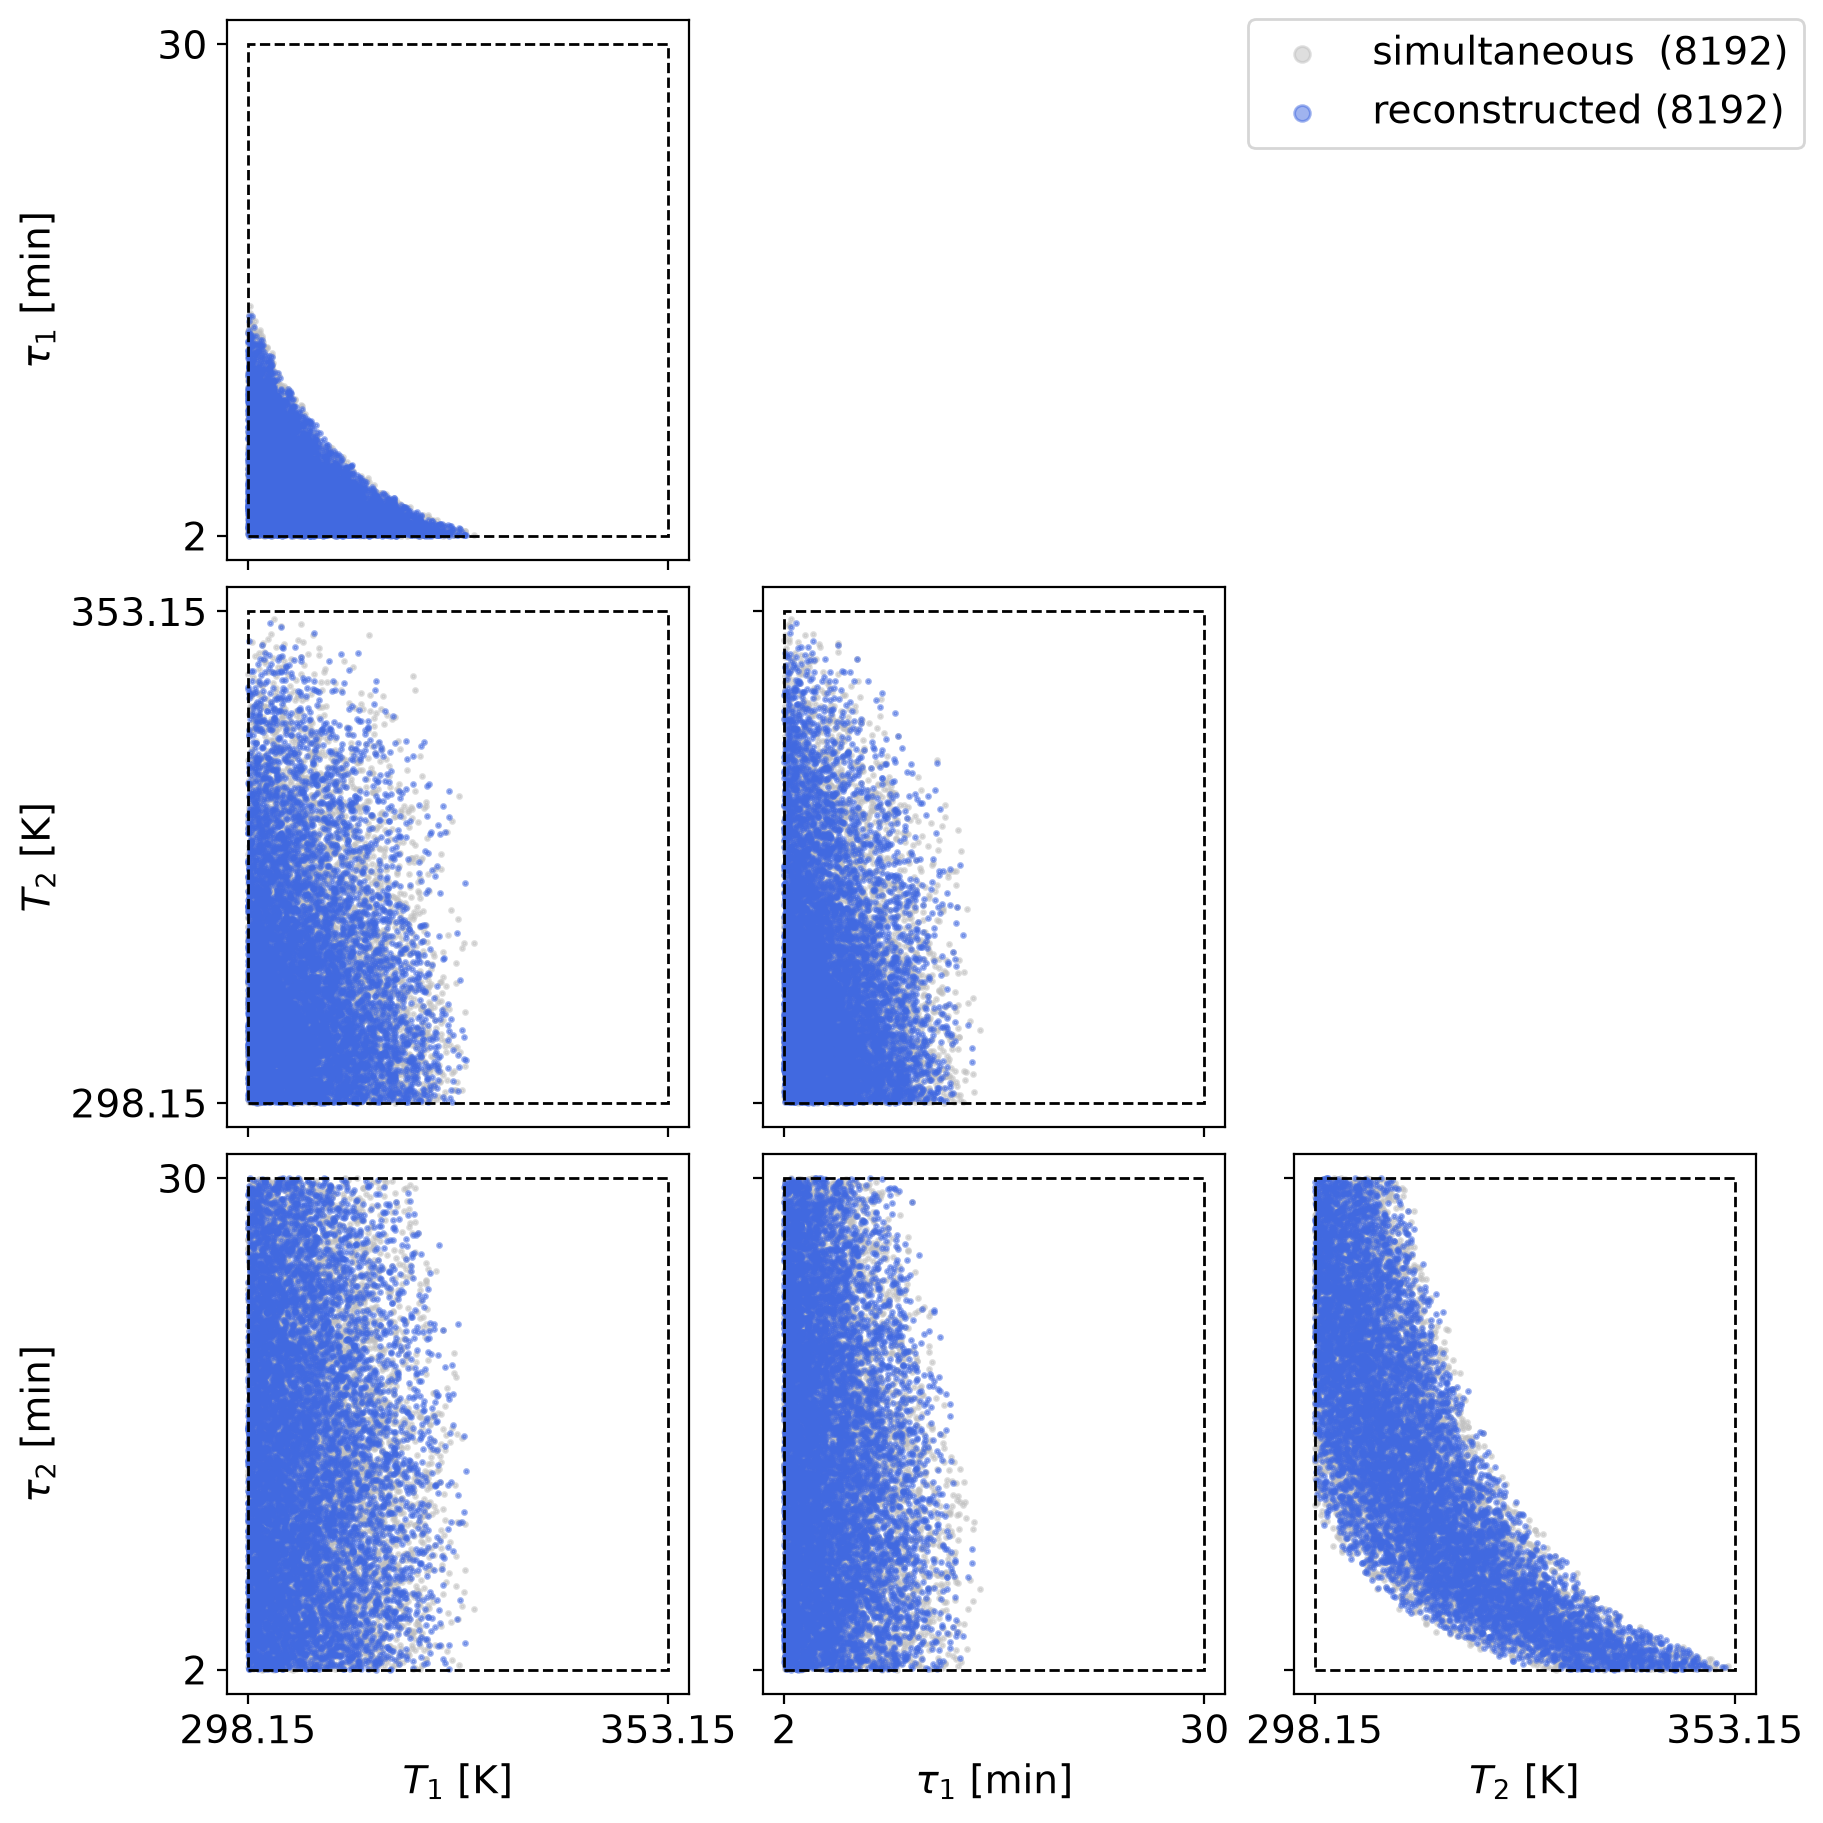

In [38]:
def simultaneous_reconstructed_corner_plot():
    live_pts = np.array(true_feas_set_based_on_surrogate_fs)
    live_pts_simult, *_ = NS_simultaneous.live_points
    grid = Corner([r"$T_1$ [K]", r"$\tau_1$ [min]", r"$T_2$ [K]", r"$\tau_2$ [min]"],
                  [[T_LO, TAU_LO, T_LO, TAU_LO], [T_HI, TAU_HI, T_HI, TAU_HI]])
    grid.scatter(live_pts_simult, s=2, alpha=0.5, color="0.75", label=f"simultaneous  ({len(live_pts_simult)})")
    grid.scatter(live_pts, s=2, alpha=0.5, color="royalblue",   label=f"reconstructed ({len(live_pts)})")
    grid.fig.legend(markerscale=4, loc="upper right")
    # grid.fig.suptitle(r"CSTR cascade: Simultaneous vs Reconstructed Evaluation")

simultaneous_reconstructed_corner_plot()

In [39]:
print("M1:", M1_counter, "R1:", R1_counter, "R2:", R2_counter, "S1:", S1_counter)

M1: 52510 R1: 52510 R2: 52510 S1: 52510


In [40]:
def benchmark():
    """comparison of simultaneous and decomposed results in flowsheet equivalents (EQ):
    1 EQ = one evaluation of the real flowsheet = (mean tear iterations) x (one call of each unit)"""
    n_eval_sim = NS_simultaneous.stats.numfct
    iters_per_eval = n_iter_sim / n_eval_sim
    eq = lambda n_iter: n_iter / iters_per_eval
    # training: N_UNIT_OP_SBL samples per unit = N_UNIT_OP_SBL calls of each of the four units
    cost_init, cost_train, cost_ver = eq(n_iter_init), eq(N_UNIT_OP_SBL), eq(n_iter_val)
    cost_dec = cost_init + cost_train + cost_ver
    print(f"decomposition: {cost_dec:.0f} EQ (initialisation {cost_init:.0f}, training {cost_train:.0f}, "
          f"verification {cost_ver:.0f} for {n_verified} candidates; "
          f"surrogate sampling {NS_simultaneous_surr.stats.numfct} evaluations at no flowsheet cost)")
    print(f"true feasible rate {100 * len(true_feas_set_based_on_surrogate_fs) / n_verified:.2f} %")
    print(f"simultaneous {n_eval_sim} EQ ({iters_per_eval:.2f} tear iterations per evaluation)")
    print(f"reduction: {100 * (1 - cost_dec / n_eval_sim):.1f} %")

benchmark()

decomposition: 10403 EQ (initialisation 40, training 1623, verification 8741 for 8542 candidates; surrogate sampling 377856 evaluations at no flowsheet cost)
true feasible rate 95.90 %
simultaneous 178432 EQ (5.05 tear iterations per evaluation)
reduction: 94.2 %


In [41]:
def get_fraction_of_surrogate_true_feasibility():
    """
    Computes the fraction of the points suggested feasible by the
    surrogate flowsheet, that are actually feasible on real flowsheet
    """
    counter = 0
    for cand in surr_candidates:
        sim_res = sim_forward_real(*cand)
        if (sim_res.converged):
            if (constraints_satisfied(c_R1=sim_res.c_R1, c_R2=sim_res.c_R2)):
                counter += 1

    print("true feasible:", counter/len(surr_candidates))
                

get_fraction_of_surrogate_true_feasibility()

true feasible: 0.95892333984375
